**MNIST** 손글씨 숫자 분류 문제를 세 가지 다른 신경망 아키텍처
- 완전연결 신경망: 모든 뉴런이 다음 층의 모든 뉴런과 연결된 가장 기본적인 신경망 구조 
- 기본 합성곱 신경망: 이미지 특징을 추출하기 위해 합성곱과 풀링을 사용하는 신경망
- LeNet-5: 숫자 인식(MNIST)용으로 만든 초기 CNN 구조로, 합성곱+풀링+FC 층으로 구성된 대표적인 고전 모델

사용해 해결하고 그 *성능 비교*

In [1]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import numpy as np
import pandas as pd

In [2]:
# MNIST 불러오기
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [3]:
# 완전연결 신경망(NN)용 전처리
X_train_nn = X_train.reshape(-1, 784) / 255.0
X_test_nn = X_test.reshape(-1, 784) / 255.0

- reshape(-1, 784): 28×28 이미지를 1D(784) **벡터로 펼친다**.
- /255.0: 픽셀 값을 0~1로 **정규화한다**.

In [4]:
# CNN(합성곱 신경망)용 전처리
X_train_cnn = X_train.reshape(-1, 28, 28, 1) / 255.0
X_test_cnn = X_test.reshape(-1, 28, 28, 1) / 255.0

- reshape(-1, 28, 28, 1): 28×28 이미지에 채널 1개(흑백)를 추가해 CNN 입력 형태(4D)로 만든다. (batch_size, height, width, channels)
- /255.0: 동일하게 정규화.

In [5]:
# 레이블 원-핫 변환
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

In [6]:
print(X_train_nn.shape)
print(X_train_cnn.shape)
print(y_train_cat.shape)

(60000, 784)
(60000, 28, 28, 1)
(60000, 10)


- NN 데이터: 이미지를 1D로 펼쳐 공간 정보가 사라짐.
- CNN 데이터: 2D 형태를 유지해 주변 픽셀 관계까지 학습 가능.

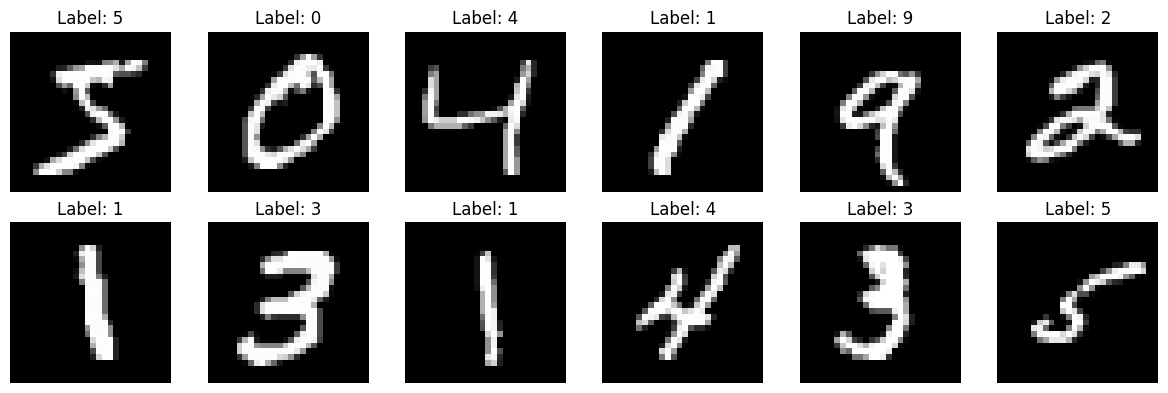

In [7]:
# 이미지 샘플 시각화 (처음 12개)
plt.figure(figsize=(12, 4))
for i in range(12):
    plt.subplot(2, 6, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
# 결과 시각화 함수
def plot_history(history, title):
    plt.rcParams['font.family'] ='Malgun Gothic'
    plt.rcParams['axes.unicode_minus'] =False
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(title)
    axs[0].plot(history.history['accuracy'], label='train acc')
    axs[0].plot(history.history['val_accuracy'], label='val acc')
    axs[0].set_title("Accuracy")
    axs[0].legend()
    axs[1].plot(history.history['loss'], label='train loss')
    axs[1].plot(history.history['val_loss'], label='val loss')
    axs[1].set_title("Loss")
    axs[1].legend()
    plt.show()

In [9]:
# 혼동 행렬 출력
def evaluate_and_plot_confusion(model, X_test, y_test, title):
    y_pred = np.argmax(model.predict(X_test), axis=1)
    acc = accuracy_score(y_test, y_pred)
    print(f"{title} - Test Accuracy: {acc:.4f}")
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm)
    disp.plot(cmap='Blues')
    plt.title(title)
    plt.grid(False)
    plt.show()

# 완전연결신경망 (FCNN, Fully Connected Neural Network)

모든 뉴런이 다음 층의 모든 뉴런과 연결된 Dense(=Fully Connected) 레이어들로 이루어진 모델

In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [11]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) # Keras에서 자주 나타나는 입력 정의 방식 관련 경고 무시

model_nn = Sequential([
    Dense(512, activation='relu', input_shape=(784,)),
    Dense(10, activation='softmax')
])

In [12]:
model_nn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 512)                 │         401,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           5,130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 407,050 (1.55 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

- dense_2 (Dense): 784 × 512 + 512 = 401,920
- dense_3 (Dense): 512 × 10 + 10 = 5,130

In [13]:
model_nn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history_nn = model_nn.fit(X_train_nn, y_train_cat, validation_split=0.1, epochs=10, batch_size=128, verbose=1)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8560 - loss: 0.4940 - val_accuracy: 0.9692 - val_loss: 0.1173
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9626 - loss: 0.1295 - val_accuracy: 0.9763 - val_loss: 0.0907
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9789 - loss: 0.0721 - val_accuracy: 0.9762 - val_loss: 0.0808
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9844 - loss: 0.0538 - val_accuracy: 0.9790 - val_loss: 0.0719
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9891 - loss: 0.0384 - val_accuracy: 0.9792 - val_loss: 0.0689
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9926 - loss: 0.0268 - val_accuracy: 0.9817 - val_loss: 0.0678
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9958 - loss: 0.0185 - val_accuracy: 0.9808 - val_loss: 0.0672
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9958 - loss: 0.0171 - val_accuracy: 0.

**1st Epoch 로그 설명**

- Epoch 1/10 → 전체 10번 학습 중 첫 번째 반복
- 422/422 → 훈련 데이터 54,000장을 422개의 배치로 모두 처리
- 2s 3ms/step → 전체 epoch 학습에 2초 걸렸고, 배치 한 개 처리에 평균 3ms.
- accuracy: 0.8560 → 훈련 데이터(54,000장) 기준 정확도 85.60%.
- loss: 0.4940 → 훈련 손실(훈련 데이터 예측 오류 정도) = 0.4940.
- val_accuracy: 0.9692 → 검증 데이터(6,000장) 기준 정확도 96.92%.
- val_loss: 0.1173 → 검증 손실(일반화 성능 지표) = 0.1173.

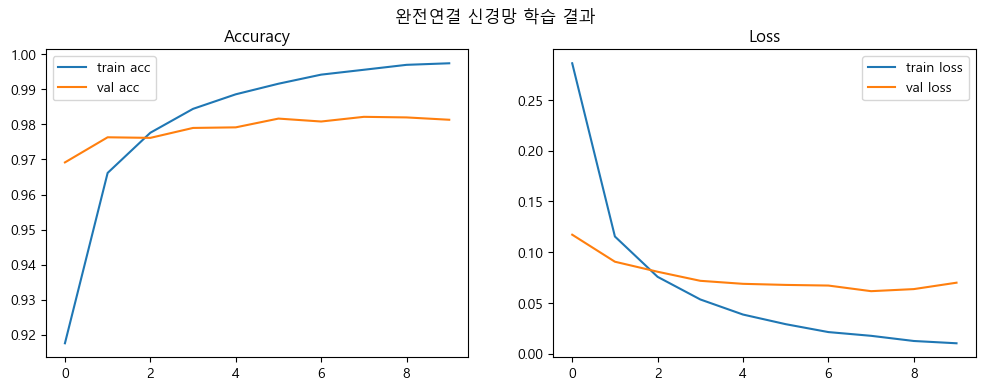

In [14]:
plot_history(history_nn, "완전연결 신경망 학습 결과")

- 훈련 정확도는 계속 상승
- 검증 정확도는 중간부터 plateau(평탄)
- → 훈련은 계속되지만 검증은 이미 최대 수준 근처에서 유지

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 792us/step
완전연결 신경망 혼동행렬 - Test Accuracy: 0.9808


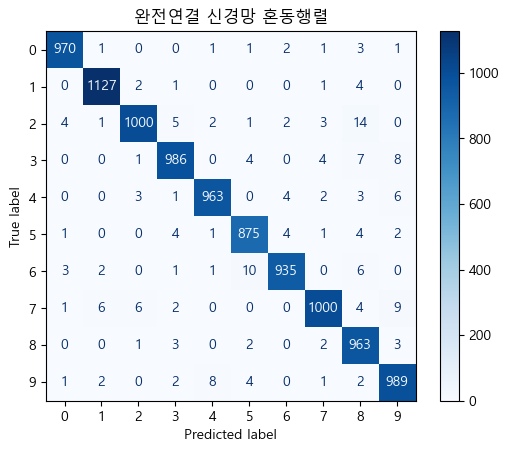

In [15]:
evaluate_and_plot_confusion(model_nn, X_test_nn, y_test, "완전연결 신경망 혼동행렬")

- 가로축: 모델이 예측한 숫자
- 세로축: 실제 정답 숫자
    - 대각선 숫자는 “정답을 맞춘 개수”
    - 대각선 바깥 숫자는 “틀린 개수”

# 합성곱신경망 (CNN)

In [17]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten

# Conv2D: 필터로 이미지의 특징을 뽑는 레이어.
# MaxPooling2D: 특징 맵을 줄여 계산량을 줄이고 핵심만 남기는 레이어.
# Flatten: 특징 맵을 1차원 벡터로 펼치는 레이어.

In [20]:
model_cnn = Sequential([
    Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)), # padding='valid' (기본값)
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

- padding='valid' (기본값): 패딩 없음 → 출력 크기 줄어듦 / 28×28 → 26×26 --> 필터가 이미지 안쪽만 지나가도록 함
- padding='same' : 패딩을 넣어 크기를 유지 / 28×28 → 그대로 28×28 --> 필터가 가장자리에서도 움직일 수 있게 주변을 0 채워줌

**레이어별 간단 설명**

Conv2D(32, 3×3) → 32개의 필터로 작은 특징을 추출.

MaxPooling2D(2×2) → 특징 맵 크기를 절반으로 줄여 중요한 정보만 남김.

Conv2D(64, 3×3) → 더 많은 필터로 더 복잡한 특징을 추출.

MaxPooling2D(2×2) → 또 한 번 크기 축소.

Flatten() → 2D 특징 맵을 1D 벡터로 펼쳐 Dense에 전달.

Dense(64, relu) → 추출된 특징을 기반으로 학습하는 완전연결층.

Dense(10, softmax) → 숫자 0~9 분류를 위한 출력층.

In [19]:
model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │         102,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

- Conv2D 파라미터 계산: (kernel_height×kernel_width×in_channels×out_channels)+out_channels 
- Dense 파라미터 계산: (in_units×out_units)+out_units

**!** NN 모델(407,050)보다 파라미터 수가 훨씬 적음

In [21]:
# 컴파일
model_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 학습
history_cnn = model_cnn.fit(X_train_cnn, y_train_cat,
                            validation_split=0.1,
                            epochs=10, batch_size=128, verbose=1)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8358 - loss: 0.5575 - val_accuracy: 0.9800 - val_loss: 0.0691
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9788 - loss: 0.0674 - val_accuracy: 0.9862 - val_loss: 0.0469
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9859 - loss: 0.0447 - val_accuracy: 0.9895 - val_loss: 0.0360
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9891 - loss: 0.0355 - val_accuracy: 0.9895 - val_loss: 0.0367
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9913 - loss: 0.0272 - val_accuracy: 0.9887 - val_loss: 0.0407
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9935 - loss: 0.0220 - val_accuracy: 0.9892 - val_loss: 0.0361
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9949 - loss: 0.0165 - val_accuracy: 0.9905 - val_loss: 0.0346
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9952 - loss: 0.0145 - val_accuracy: 0.

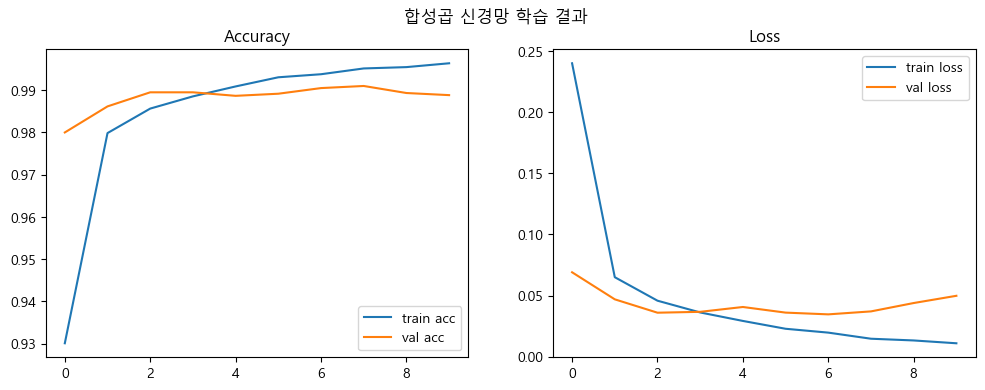

In [22]:
# 학습 그래프 출력
plot_history(history_cnn, "합성곱 신경망 학습 결과")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
합성곱 신경망 혼동행렬 - Test Accuracy: 0.9897


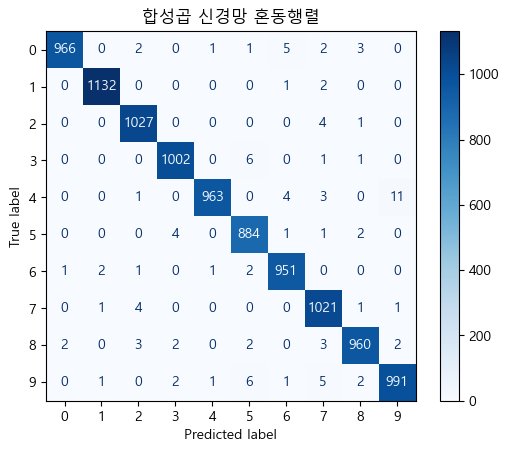

In [23]:
evaluate_and_plot_confusion(model_cnn, X_test_cnn, y_test, "합성곱 신경망 혼동행렬")

# LeNet-5

1998년에 Yann LeCun이 만든 초기 CNN 모델로, 손글씨 숫자 인식(MNIST)의 원조 모델

In [24]:
from tensorflow.keras.layers import AveragePooling2D

In [35]:
# LeNet-5 구조 정의
model_lenet = Sequential([
    Conv2D(6, kernel_size=(5, 5), activation='tanh', input_shape=(28, 28, 1)),
    AveragePooling2D(pool_size=(2, 2), strides=2), # 특징 맵을 평균 풀링으로 절반 크기로 줄임
    Conv2D(16, kernel_size=(5, 5), activation='tanh'),
    AveragePooling2D(pool_size=(2, 2), strides=2),
    Conv2D(120, kernel_size=(5, 5), activation='tanh', padding='same'),
    Flatten(),
    Dense(84, activation='tanh'),
    Dense(10, activation='softmax')  # 원래는 RBF(radial basis function)지만 softmax로 대체 - TensorFlow/Keras/PyTorch에는 기본 RBF 출력층이 없음
])

In [28]:
model_lenet.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)                    │ (None, 24, 24, 6)           │             156 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling2d_2                  │ (None, 12, 12, 6)           │               0 │
│ (AveragePooling2D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 8, 8, 16)            │           2,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling2d_3                  │ (None, 4, 4, 16)            │               0 │
│ (AveragePooling2D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 4, 4, 120)           │          48,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 1920)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 84)                  │         161,364 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 10)                  │             850 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 212,906 (831.66 KB)

 Trainable params: 212,906 (831.66 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
model_lenet.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_lenet = model_lenet.fit(X_train_cnn, y_train_cat,
                                validation_split=0.1,
                                epochs=10, batch_size=128, verbose=1)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8239 - loss: 0.5826 - val_accuracy: 0.9548 - val_loss: 0.1632
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9442 - loss: 0.1835 - val_accuracy: 0.9670 - val_loss: 0.1191
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9605 - loss: 0.1300 - val_accuracy: 0.9720 - val_loss: 0.0936
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9715 - loss: 0.0957 - val_accuracy: 0.9802 - val_loss: 0.0711
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9774 - loss: 0.0757 - val_accuracy: 0.9797 - val_loss: 0.0677
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9815 - loss: 0.0619 - val_accuracy: 0.9845 - val_loss: 0.0571
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9839 - loss: 0.0531 - val_accuracy: 0.9840 - val_loss: 0.0563
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9871 - loss: 0.0440 - val_accuracy: 0.

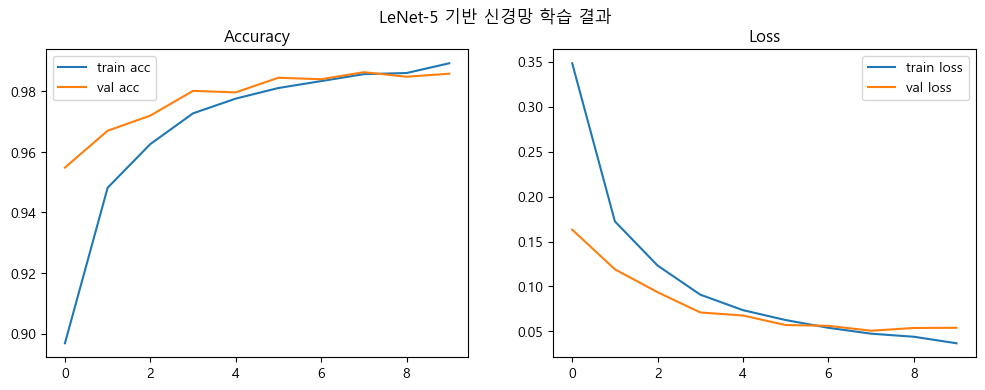

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
LeNet-5 기반 신경망 혼동행렬 - Test Accuracy: 0.9833


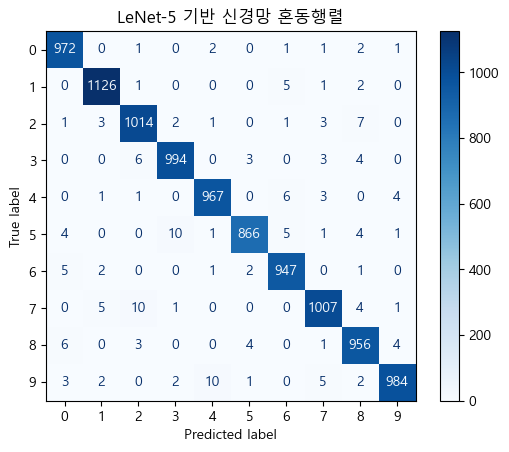

In [30]:
plot_history(history_lenet, "LeNet-5 기반 신경망 학습 결과")
evaluate_and_plot_confusion(model_lenet, X_test_cnn, y_test, "LeNet-5 기반 신경망 혼동행렬")

# 성능 비교 (완전연결, CNN, LeNet-5)
세 모델의 성능을 비교하기 위해 리스트를 준비하고, 루프를 돌며 각 모델의 테스트 정확도(Test Accuracy), 테스트 손실(Test Loss), 총 파라미터 수를 계산하여 비교

In [31]:
model_names = ["완전연결", "CNN", "LeNet-5"]
models = [model_nn, model_cnn, model_lenet]
histories = [history_nn, history_cnn, history_lenet]
X_tests = [X_test_nn, X_test_cnn, X_test_cnn]
y_true = y_test

In [32]:
summary = []
for name, model, hist, X in zip(model_names, models, histories, X_tests):
    y_pred = np.argmax(model.predict(X), axis=1)
    acc = accuracy_score(y_true, y_pred)
    loss = model.evaluate(X, to_categorical(y_true, 10), verbose=0)[0]
    params = model.count_params()
    summary.append({
        "모델": name,
        "정확도": round(acc, 4),
        "Loss": round(loss, 4),
        "파라미터 수": params
    })

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 721us/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


In [33]:
# 요약표 출력
df_summary = pd.DataFrame(summary)
df_summary

,모델,정확도,Loss,파라미터 수
0,완전연결,0.9808,0.0647,407050
1,CNN,0.9897,0.0350,121930
2,LeNet-5,0.9833,0.0474,212906
